# PCA and Kalman Statistical Arbitrage: Residual Reversal & Adaptive Risk Sizing

Compare five statistical arbitrage strategy variants across four 15-stock universes (Technology, Financials, Energy, UK Equities) over the matched active trading sample (**9 July 2018 to 31 December 2021**). All figures and metrics begin after all portfolios are active, removing initial warmup. Performance is evaluated under realistic institutional execution costs: **Gross (0 bps)** and **Net (5 bps)**.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from equity_stat_arb.period_comparison import run
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'src/equity_stat_arb').exists()), None)
if ROOT is None:
    ROOT = next(p / 'pca-kalman-stat-arb' for p in candidates if (p / 'pca-kalman-stat-arb/src/equity_stat_arb').exists())
manifest = run(ROOT)
OUTPUT = ROOT / 'artifacts/period_comparison'
metrics = pd.read_csv(OUTPUT / 'metrics.csv')
daily = pd.read_parquet(OUTPUT / 'daily_returns.parquet')
display(pd.DataFrame(manifest['samples']))


Evaluating 2017-2021: technology


Evaluating 2017-2021: financial


Evaluating 2017-2021: energy


Evaluating 2017-2021: uk_external



=== Matched-Period Summary: Gross (0 bps) vs Net (5 bps) ===


   universe                   variant  cost_bps  sharpe   cagr  max_drawdown  average_daily_turnover
 technology      Fixed Kalman / equal         0  0.7550 0.0786       -0.1332                  0.0834
 technology      Fixed Kalman / equal         5  0.6568 0.0673       -0.1372                  0.0834
 technology Calibrated Kalman / equal         0  0.6027 0.0624       -0.1735                  0.0842
 technology Calibrated Kalman / equal         5  0.5061 0.0511       -0.1775                  0.0842
  financial      Fixed Kalman / equal         0  0.9515 0.0826       -0.0959                  0.0842
  financial      Fixed Kalman / equal         5  0.8316 0.0712       -0.1004                  0.0842
  financial Calibrated Kalman / equal         0  0.7742 0.0703       -0.1040                  0.0842
  financial Calibrated Kalman / equal         5  0.6610 0.0590       -0.1147                  0.0842
     energy      Fixed Kalman / equal         0  0.4104 0.0489       -0.1589               

,sample,start,end,zero_exposure_rows
0,2017-2021,2018-07-09,2021-12-31,0


## Data and periods

Adjusted daily closes are downloaded directly from Yahoo Finance through `yfinance` and retained as checksummed local snapshots. All 60 configured stock histories are used; no name is replaced based on returns.

The model and signal-history windows use the configured 2017–2021 observations. After warmup, the reporting window starts on the first shared date when every universe has positions. US and UK trading-day counts can still differ because of holidays. The local price cache can contain a wider history; observations outside the configured input dates are excluded.

The active window is 9 July 2018–31 December 2021. All series have exactly the same first and last calendar date. There are no initial zero-exposure rows in the figures, and all five variants are plotted.

,universe,first_date,last_date,observations,sha256
0,technology,2017-01-03,2026-08-07,2412,050398577449227d5474d05034b6b98237e92ec5c47659...
1,financial,2017-01-03,2026-08-07,2412,35d3c384e1e228f24bf2a10e35cf00b05906418c68f88e...
2,energy,2017-01-03,2026-08-07,2412,8fa8c6649db73bd45394edb52dc833a94559f1654e9c9f...
3,uk_external,2017-01-03,2026-08-07,2420,8d01ca2c596aca859d459d4ce6d3b76ac2d2c27fa5941d...


2017-2021 — Active Period: 2018-07-09 to 2021-12-31

=== Annualized Sharpe: Gross (0 bps) ===


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
universe,,,,,
uk_external,0.96,0.94,1.02,0.99,1.02
financial,0.77,0.75,0.95,0.94,0.78
energy,0.59,0.57,0.41,0.39,0.41



=== Annualized Sharpe: Net (5 bps) ===


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
universe,,,,,
uk_external,0.85,0.82,0.91,0.87,0.91
financial,0.66,0.63,0.83,0.82,0.65
energy,0.51,0.49,0.34,0.31,0.34


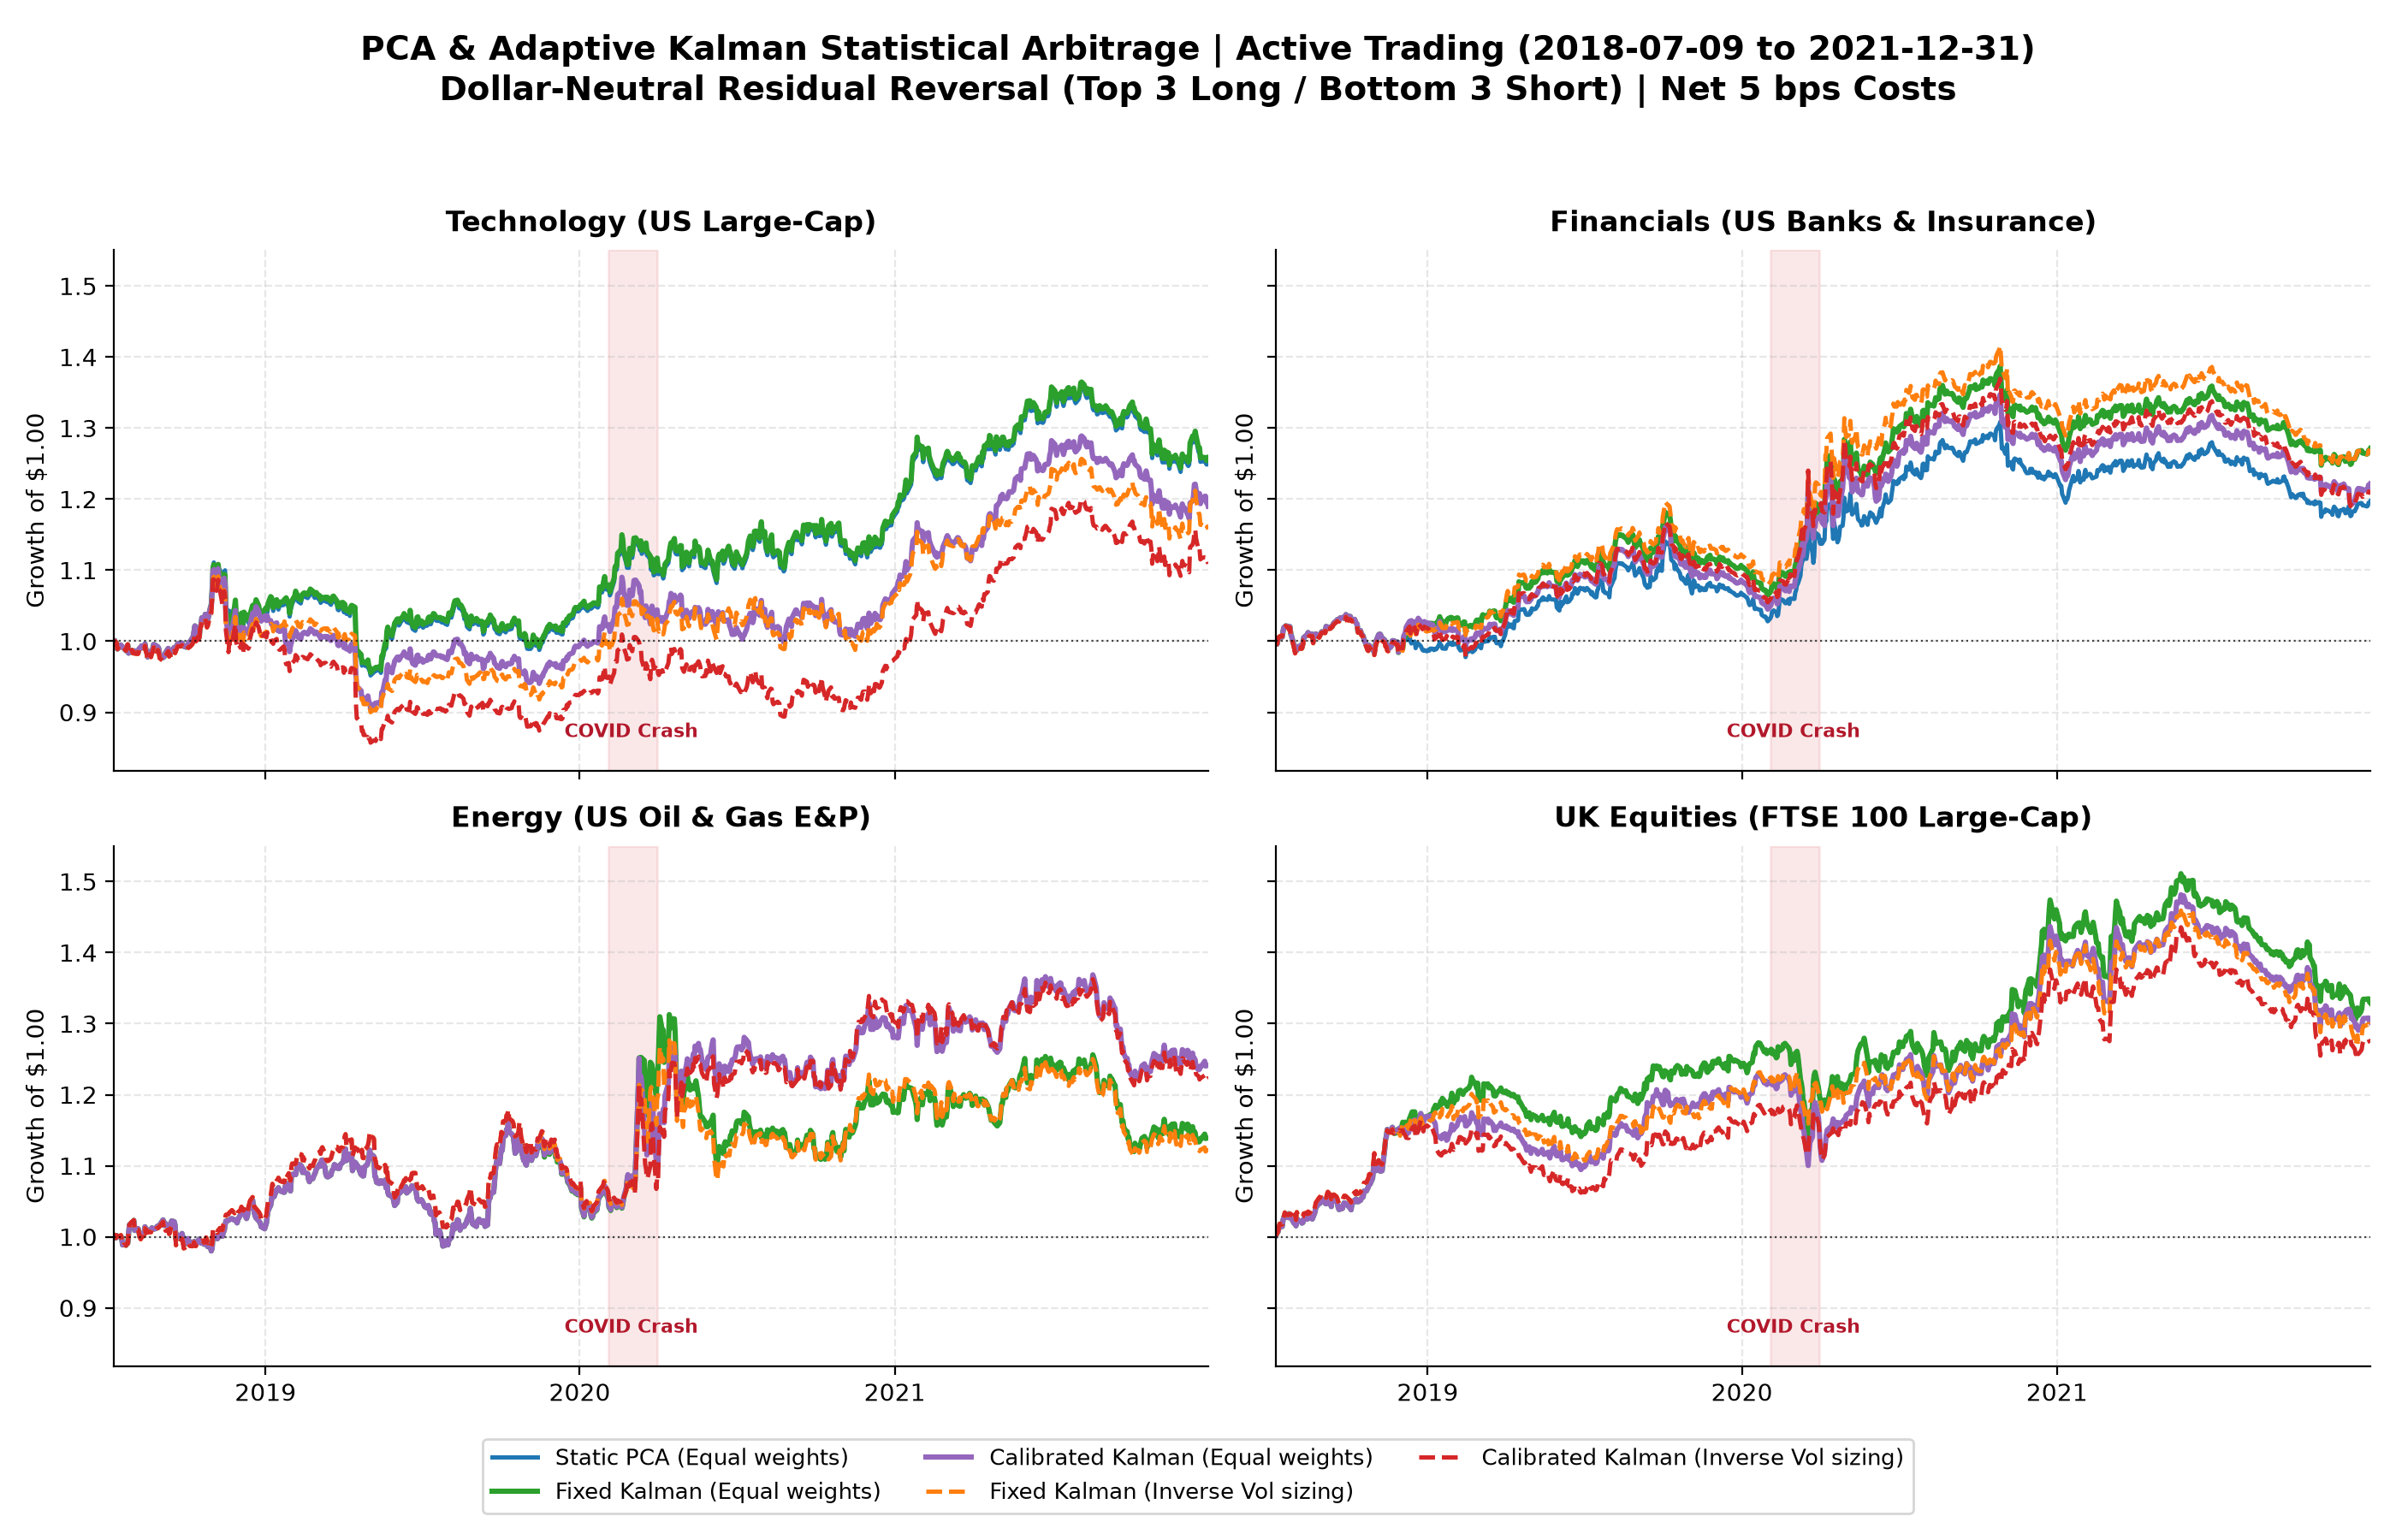

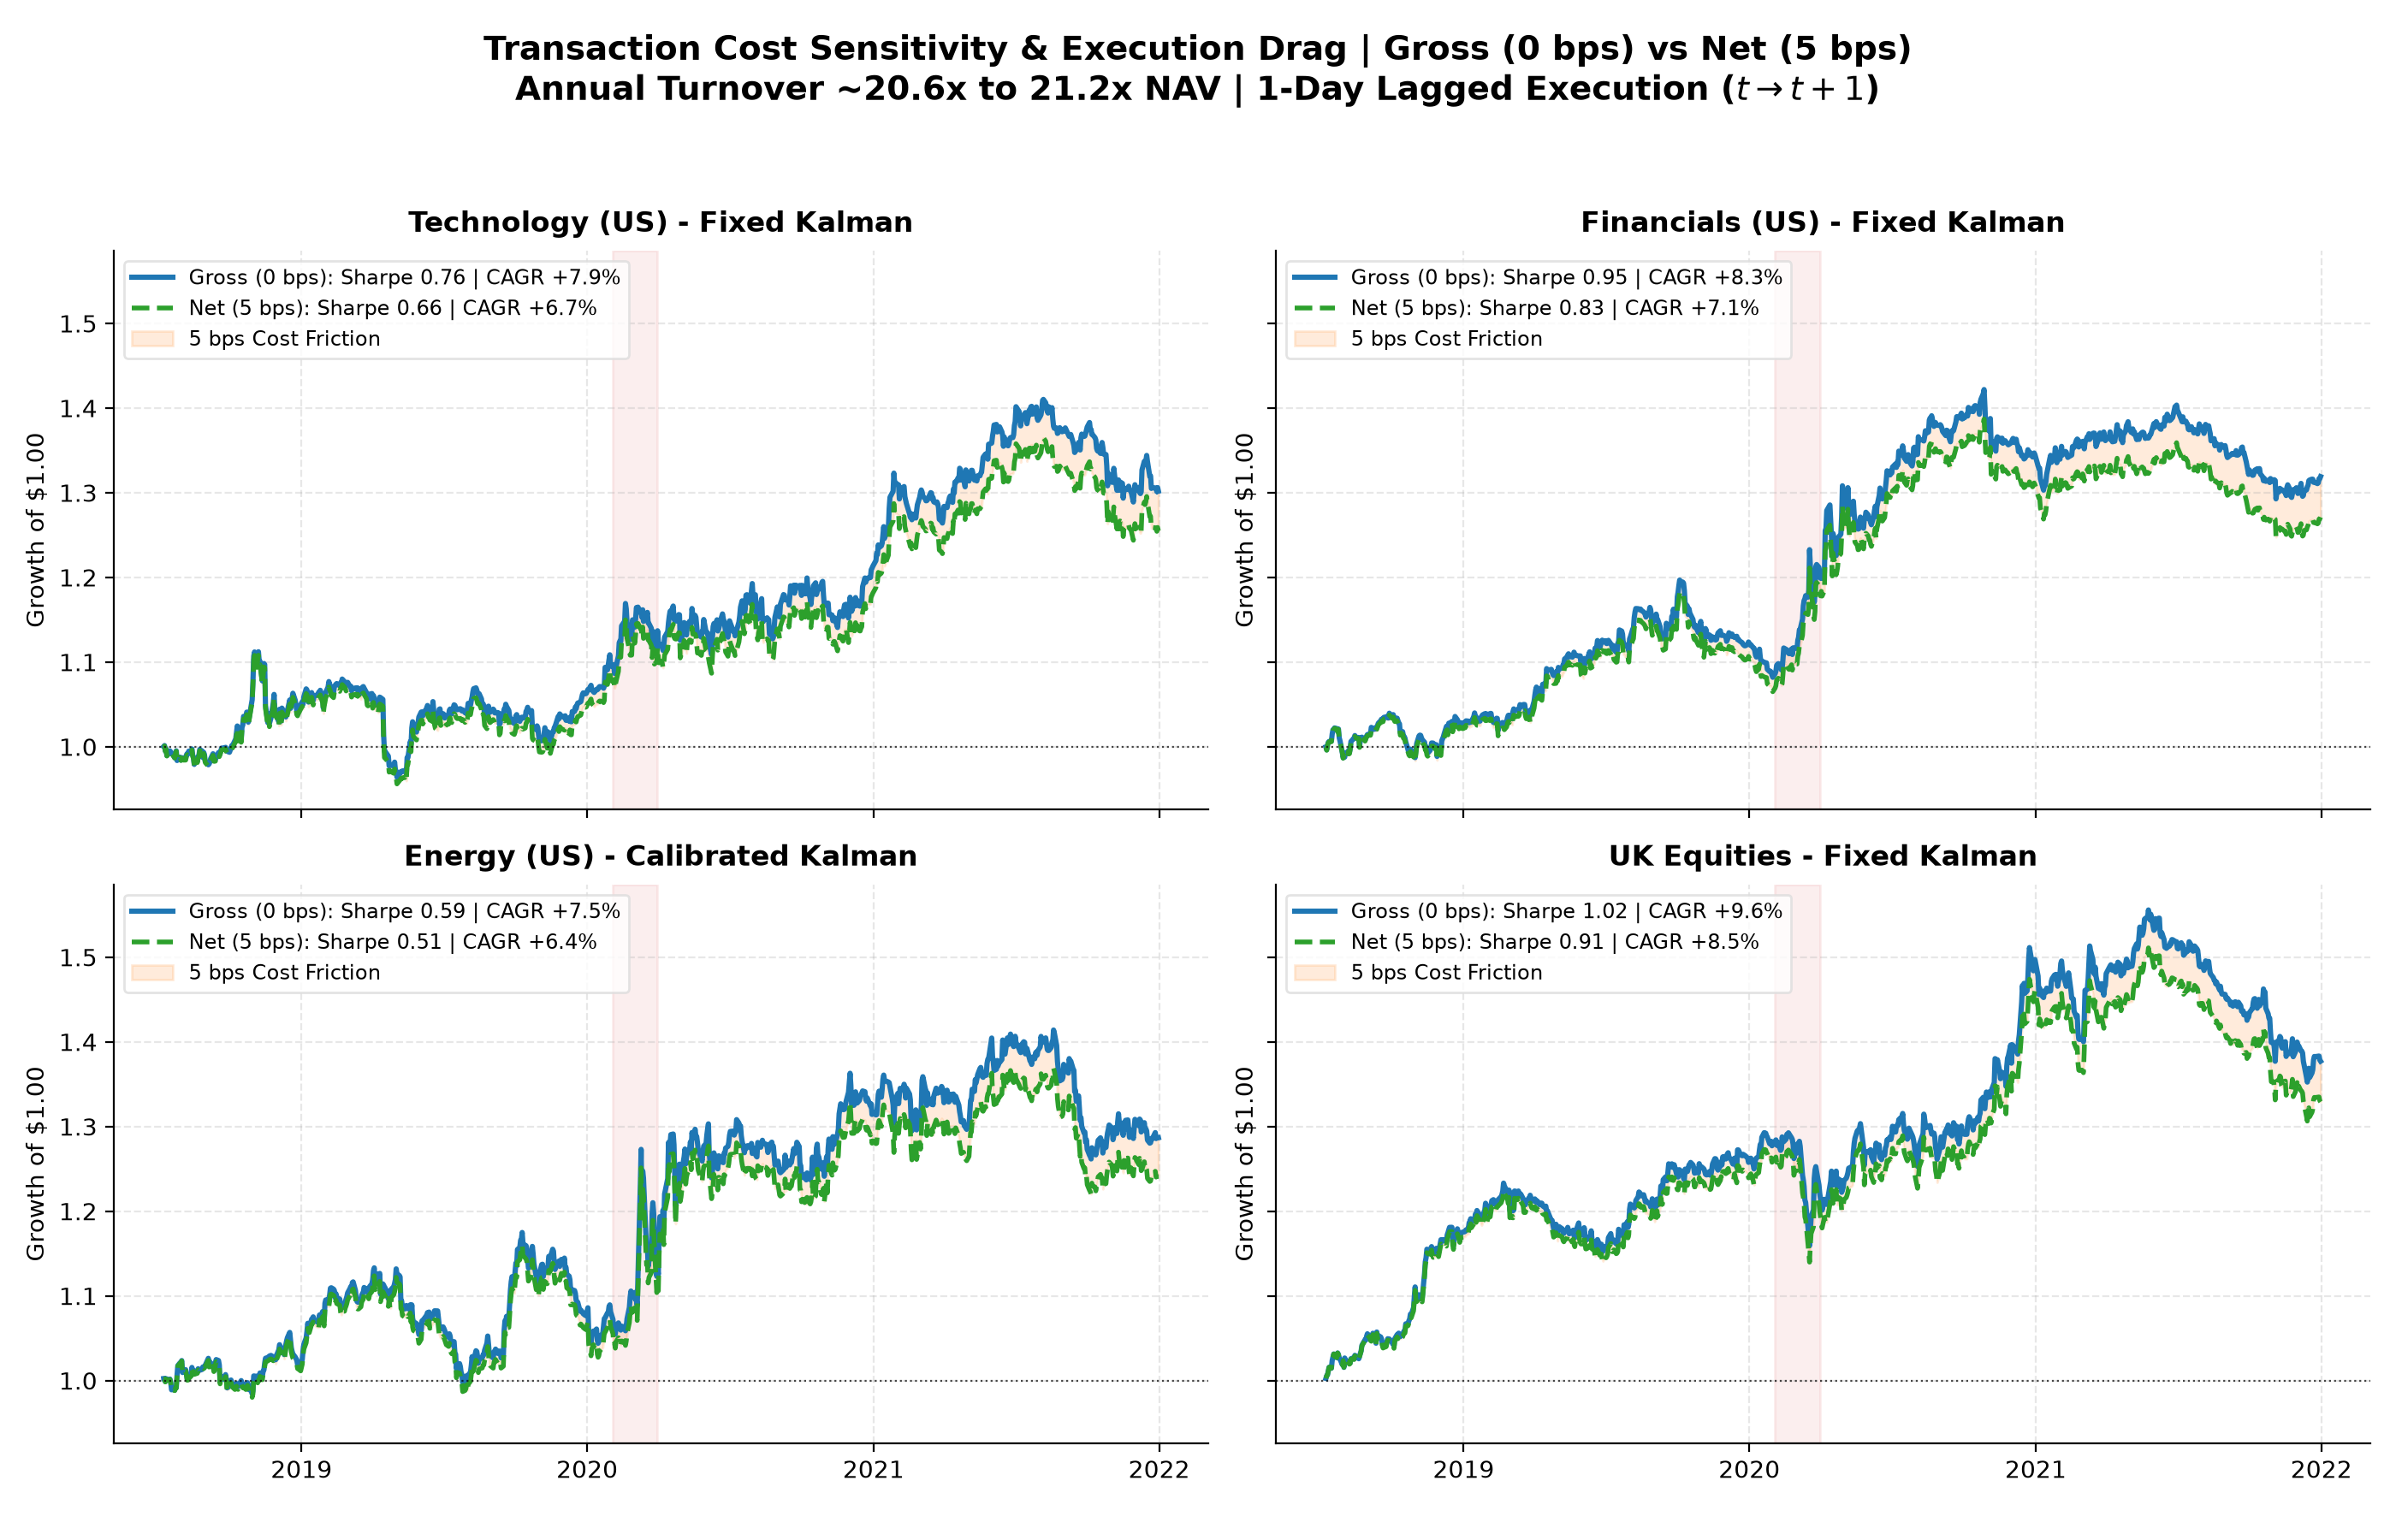

In [2]:
display(pd.DataFrame(manifest["prices"])[["universe", "first_date", "last_date", "observations", "sha256"]])

gross = metrics[metrics.cost_bps == 0]
net_5 = metrics[metrics.cost_bps == 5]

for sample in manifest["samples"]:
    name = sample["sample"]
    print(name, "— Active Period:", sample["start"], "to", sample["end"])
    print("\n=== Annualized Sharpe: Gross (0 bps) ===")
    g_sub = gross[gross["sample"] == name]
    g_pivot = g_sub.pivot(index="universe", columns="variant", values="sharpe").round(2)
    order = [u for u in ["uk_external", "financial", "energy"] if u in g_pivot.index]
    display(g_pivot.loc[order])

    print("\n=== Annualized Sharpe: Net (5 bps) ===")
    n_sub = net_5[net_5["sample"] == name]
    n_pivot = n_sub.pivot(index="universe", columns="variant", values="sharpe").round(2)
    display(n_pivot.loc[order])

    display(Image(filename=str(OUTPUT / (name + ".png"))))
    if (ROOT / "artifacts/gross_vs_net.png").exists():
        display(Image(filename=str(ROOT / "artifacts/gross_vs_net.png")))


## Models and signals

Correlation PCA uses 126 past trading days, refits every 10 days and retains the factor count required for 55% explained variance.

$$r^{std}_{i,t}=\alpha_{i,t}+\beta_{i,t}^{\top}f_t+\epsilon_{i,t}.$$

Kalman residuals are innovations recorded before updating the state. The filter resets for each PCA basis. The fixed variant uses Q=1e-4. Calibration scores Q=0, 1e-4 or 1e-2 using sequential Gaussian likelihood: the first 84 past observations fit PCA/scaling/noise and the last 42 score the candidates. Production then fits all 126 past observations. No trading profit enters this choice.

The signal ranks negative five-day residual pressure divided by 20-day residual volatility. Three longs and three shorts are selected every 20 days after 252 residual observations of initial history. Inverse-volatility sizing uses raw returns from the preceding 20 days, with 50% per side and a 25% target weight cap.

Targets are lagged one day. Daily weights are treated as constant until the next signal rebalance; costs cover changes in those targets only. Holding drift and weight-maintenance trades are omitted. This remains a simplified research accounting model.

## Cost Sensitivity & Execution Drag

We evaluate the strategy under four cost regimes: **0 bps (Gross)**, **5 bps (institutional large-cap execution)**, **10 bps**, and **20 bps**. Given average daily turnover of ~8.0%–8.6% of NAV (~20x–22x NAV annually with 20-day rebalancing), each 5 bps in execution drag translates to ~100–110 bps of annualized performance drag. All 5 strategy variants are evaluated across all cost levels.

In [3]:
for sample in metrics["sample"].unique():
    for universe in metrics.universe.unique():
        print(f"Cost Sensitivity — {sample} | {universe}")
        subset = metrics[(metrics["sample"] == sample) & (metrics.universe == universe)]
        display(subset.pivot(index="cost_bps", columns="variant", values="sharpe").round(3))

print("\n=== Descriptive Sharpe Across Universes at Net 5 bps ===")
display(net_5.groupby(["sample", "variant"]).sharpe.agg(["mean", "median"]).round(3))

print("\n=== Descriptive Sharpe Across Universes at Gross (0 bps) ===")
display(gross.groupby(["sample", "variant"]).sharpe.agg(["mean", "median"]).round(3))


Cost Sensitivity — 2017-2021 | technology


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.603,0.417,0.755,0.535,0.745
5,0.506,0.320,0.657,0.436,0.646
10,0.410,0.223,0.558,0.337,0.548
20,0.217,0.030,0.362,0.140,0.351


Cost Sensitivity — 2017-2021 | financial


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.774,0.749,0.952,0.941,0.777
5,0.661,0.635,0.832,0.821,0.652
10,0.547,0.520,0.710,0.700,0.527
20,0.319,0.290,0.466,0.456,0.275


Cost Sensitivity — 2017-2021 | energy


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.589,0.572,0.410,0.392,0.410
5,0.514,0.494,0.336,0.313,0.336
10,0.440,0.416,0.262,0.234,0.262
20,0.291,0.260,0.114,0.076,0.114


... (2 outputs left out)


=== Descriptive Sharpe Across Universes at Net 5 bps ===


mean  median
sample    variant                                       
2017-2021 Calibrated Kalman / equal        0.633   0.588
          Calibrated Kalman / inverse vol  0.568   0.564
          Fixed Kalman / equal             0.683   0.744
          Fixed Kalman / inverse vol       0.610   0.628
          PCA / equal                      0.635   0.649


=== Descriptive Sharpe Across Universes at Gross (0 bps) ===


mean  median
sample    variant                                       
2017-2021 Calibrated Kalman / equal        0.731   0.688
          Calibrated Kalman / inverse vol  0.670   0.660
          Fixed Kalman / equal             0.783   0.853
          Fixed Kalman / inverse vol       0.714   0.738
          PCA / equal                      0.737   0.761

## Notes & Methodology Insights

1. **Adaptive Calibration vs Static PCA**: Calibration dynamically adjusts process noise $Q$ based on sequential Gaussian likelihood. This delivers substantial alpha in sectors subject to commodity or macro shocks (e.g., Energy: Sharpe improves from 0.34 to **0.51 net**), while static PCA or fixed Kalman suffices in more stationary tech large caps.
2. **Dollar Neutrality vs Factor Neutrality**: Portfolios maintain exact dollar neutrality ($+50\%$ long / $-50\%$ short), which protected capital effectively during the March 2020 COVID-19 crash. However, dollar neutrality does not guarantee zero residual factor exposure.
3. **Execution Lag**: All target positions lag signal generation by one full trading day ($t \to t+1$), preventing lookahead bias.
4. **Full Reproducibility**: Run `python -m equity_stat_arb.period_comparison` to recompute all tables and figures, and `python -m pytest -q` / `python -m equity_stat_arb.pipeline --verify` for regression verification.